# Mumbai property prices: prediction, segments and drivers

**Question.** What should a flat in the Mumbai Metropolitan Region cost, what drives the price, and what kinds of
buyers does the market serve? Framed for a developer pricing a new launch.

**Data.** *Mumbai House Prices* (Kaggle, Dravid Vaishnav): 76,038 listings scraped from Makaan.com, with BHK, type,
project, area, price, locality, construction status and new/resale. These are **asking prices**, not registered sales.

This notebook walks through the analysis. The heavy lifting lives in `scripts/` (run `build_data.py`, `evaluate.py`,
`train.py` first); here we load their outputs and look at the results.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "app"))
from features import ZONES, LocationEncoder, project_key

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
raw = pd.read_csv(ROOT / "data/raw/mumbai.csv")
d = pd.read_parquet(ROOT / "data/listings.parquet")
raw.head()

,bhk,type,locality,area,price,price_unit,region,status,age
0,3,Apartment,Lak And Hanware The Residency Tower,685,2.50,Cr,Andheri West,Ready to move,New
1,2,Apartment,Radheya Sai Enclave Building No 2,640,52.51,L,Naigaon East,Under Construction,New
2,2,Apartment,Romell Serene,610,1.73,Cr,Borivali West,Under Construction,New
3,2,Apartment,Soundlines Codename Urban Rainforest,876,59.98,L,Panvel,Under Construction,New
4,2,Apartment,Origin Oriana,659,94.11,L,Mira Road East,Under Construction,New


## 1. Cleaning

The biggest problem is duplicates: the same flat posted again. Left in, a flat can be in both the training and test
data, so the model looks better than it is. Every rule is counted.

In [2]:
rep = json.load(open(ROOT / "data/cleaning_report.json"))
print(f"Raw rows: {rep['raw_rows']:,}   exact duplicates: {raw.duplicated().sum():,} ({raw.duplicated().mean():.0%})")
pd.DataFrame(rep["steps"]).set_index("rule")

Raw rows: 76,038   exact duplicates: 20,312 (27%)


,removed
rule,
Exact duplicate listings (same flat posted again),20312
"Villas, independent houses and penthouses (too few, a different market)",216
More than 5 bedrooms (too few to model),116
"Area under 200 or over 6,000 sq ft",62
Under 150 sq ft per bedroom (area or BHK mistyped),0
Price per sq ft in the extreme 0.5% at either end,554
Price per sq ft over 3x above or below the locality's typical value,162
Locality too small or unclear to place in a zone,18


In [3]:
print(f"Clean listings: {len(d):,} · localities: {d.Locality.nunique()} · projects: {d.Project.nunique():,}")
d.groupby("Zone").agg(listings=("Price", "size"), median_price_lakh=("price_lakh", "median"),
                      median_ppsf=("ppsf", "median"), median_area=("Area", "median")).reindex(ZONES).round(0)

Clean listings: 54,598 · localities: 175 · projects: 9,477


,listings,median_price_lakh,median_ppsf,median_area
Zone,,,,
South Mumbai,2464,376.0,31180.0,1242.0
Western Suburbs,11783,178.0,20000.0,900.0
Central Suburbs,7059,170.0,19954.0,858.0
Thane,7596,115.0,12898.0,918.0
Navi Mumbai & Panvel,7784,88.0,9010.0,1050.0
Mira Road & Vasai-Virar,10988,66.0,8709.0,741.0
Kalyan-Dombivli & beyond,6924,43.0,5889.0,695.0


Localities are grouped into **7 zones** with whole-word keyword rules (`app/places.py`), after tidying spellings
("Dombivali" → "Dombivli", "Sector-12 Kamothe" → "Kamothe"). Whole words matter: a plain substring match would put
*Kharghar* under *Khar*.

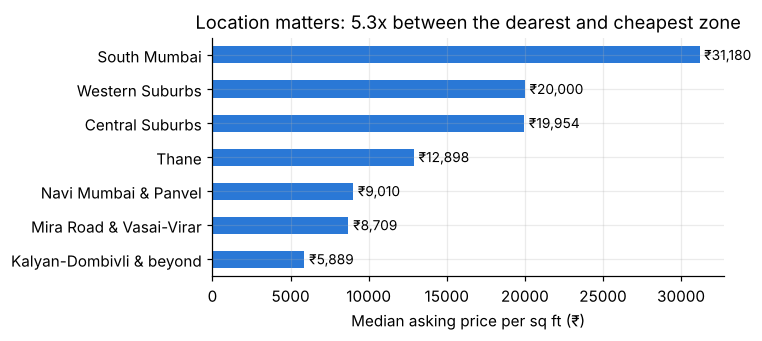

In [4]:
z = d.groupby("Zone").ppsf.median().reindex(ZONES).sort_values()
ax = z.plot.barh(color=BLUE, figsize=(7, 3.2))
ax.set_xlabel("Median asking price per sq ft (₹)"); ax.set_ylabel("")
ax.set_title(f"Location matters: {z.max() / z.min():.1f}x between the dearest and cheapest zone")
for i, v in enumerate(z): ax.text(v + 300, i, f"₹{v:,.0f}", va="center", fontsize=9)
plt.tight_layout()

## 2. The dataset I rejected first

The popular *Housing Prices in Metropolitan Areas of India* data looked like a good fit, but in every city it is two
batches. In the batch where amenities are all coded 9 ("not mentioned"), **area and bedrooms still agree, but price
barely relates to either**. The price column seems misaligned with the rest of the row, for about 70% of the data.
(`scripts/check_six_city.py`)

In [5]:
six = json.load(open(ROOT / "data/six_city_check.json"))
pd.DataFrame([{"city": c, "batch": b, **m} for c, v in six["cities"].items() for b, m in v.items()]).set_index(["city", "batch"])

rows  r_price_area  r_price_bedrooms  \
city      batch                                                     
Mumbai    Amenities listed   1156          0.79              0.77   
          Amenities missing  5769          0.22              0.23   
Delhi     Amenities listed   1716          0.90              0.54   
          Amenities missing  2393          0.42              0.26   
Bangalore Amenities listed   1617          0.90              0.69   
          Amenities missing  3904          0.31              0.20   
Chennai   Amenities listed   1768          0.88              0.72   
          Amenities missing  2539          0.22              0.15   
Hyderabad Amenities listed   1914          0.89              0.71   
Kolkata   Amenities missing  6220          0.11              0.08   

                             r_area_bedrooms  
city      batch                               
Mumbai    Amenities listed              0.90  
          Amenities missing             0.83  
Delhi     Amenities listed              0.70  
          Amenities missing             0.72  
Bangalore Amenities listed              0.80  
          Amenities missing             0.81  
Chennai   Amenities listed              0.84  
          Amenities missing             0.84  
Hyderabad Amenities listed              0.82  
Kolkata   Amenities missing             0.75

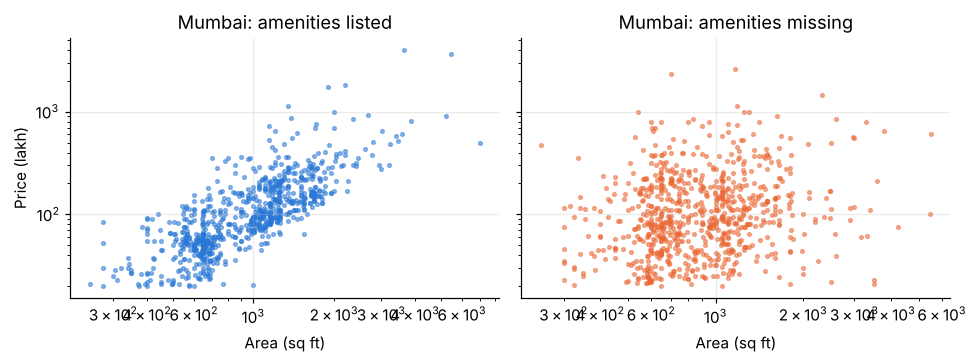

In [6]:
s = pd.DataFrame(six["mumbai_sample"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (b, g), c in zip(axes, s.groupby("batch"), [BLUE, ORANGE]):
    ax.scatter(g.area, g.price_lakh, s=6, alpha=0.5, color=c); ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"Mumbai: {b.lower()}"); ax.set_xlabel("Area (sq ft)")
axes[0].set_ylabel("Price (lakh)"); plt.tight_layout()

## 3. Features: borrowing strength for small projects

175 localities and ~9,500 projects, half of them with 1-2 listings. Each level gets a *typical log price per sq ft*,
**shrunk towards the level above** when it has few listings (an m-estimate):

    project value = (sum of its listings + 5 x locality value) / (its listings + 5)

and the same for locality → zone (weight 10) and zone → Mumbai (weight 20). Training rows get these values
**out of fold**, so a listing never sees its own price.

In [7]:
enc = LocationEncoder().fit(d)
ex = d.assign(key=project_key(d)).groupby("key").size().sort_values()
for k in [ex.index[0], ex.index[len(ex) // 2], ex.index[-1]]:
    loc = k.split(" | ")[0]
    print(f"{k[:55]:55s} listings={enc.proj_n[k]:3d}  project={np.exp(enc.proj[k]):8,.0f}  locality={np.exp(enc.loc[loc]):8,.0f}  ₹/sq ft")

Kalyan East | Reputed Builder Chandra Bhaga Dham        listings=  1  project=   5,652  locality=   6,333  ₹/sq ft
Prabhadevi | Cosmos Majestic Tower                      listings=  2  project=  36,455  locality=  36,905  ₹/sq ft
Mira Road East | Jp North Barcelona                     listings=250  project=  10,466  locality=   9,453  ₹/sq ft


## 4. Models under three honest tests

A random split flatters the model, because flats from one project land on both sides. So every model is tested three
ways (5-fold cross-validation each):

* **Known project**: random folds. A new listing in a project already on the market.
* **New project**: whole projects held out. Pricing a launch the model has never seen. *The developer's case.*
* **New locality**: whole localities held out. Only the zone is known.

In [8]:
ev = json.load(open(ROOT / "models/eval.json"))
tab = pd.DataFrame({t: {m: v["median_error_pct"] for m, v in r.items() if not m.startswith("_")} for t, r in ev.items()})
tab.columns = [f"{c}: median % error" for c in tab.columns]
tab

,Known project: median % error,New project: median % error,New locality: median % error
Baseline (locality price/sq ft x area),15.8,16.2,27.9
Linear regression,13.6,13.9,25.8
Random forest,8.4,12.5,27.2
Gradient boosting,9.2,12.7,25.1


In [9]:
pd.DataFrame({t: {m: v["within_20_pct"] for m, v in r.items() if not m.startswith("_")} for t, r in ev.items()}).add_suffix(": % within ±20%")

,Known project: % within ±20%,New project: % within ±20%,New locality: % within ±20%
Baseline (locality price/sq ft x area),60.2,59.0,33.8
Linear regression,66.9,66.1,38.9
Random forest,83.1,69.6,37.1
Gradient boosting,81.5,69.3,40.3


**Reading it.**
* Knowing the project nearly halves the error against the simple locality rule.
* For a brand-new project the best model is about ±12%: location and size explain most of the price; builder,
  floor, view and amenities (not in the data) explain the rest.
* For a new locality every model struggles (25%+), and the plain linear model is close to the best tree: with only the
  zone to go on, there is little for a complex model to add.
* Deployed model: gradient boosting with a monotonic constraint (price only rises with area). The random forest was a
  little better on known projects, but its file is ~98 MB against ~2 MB.

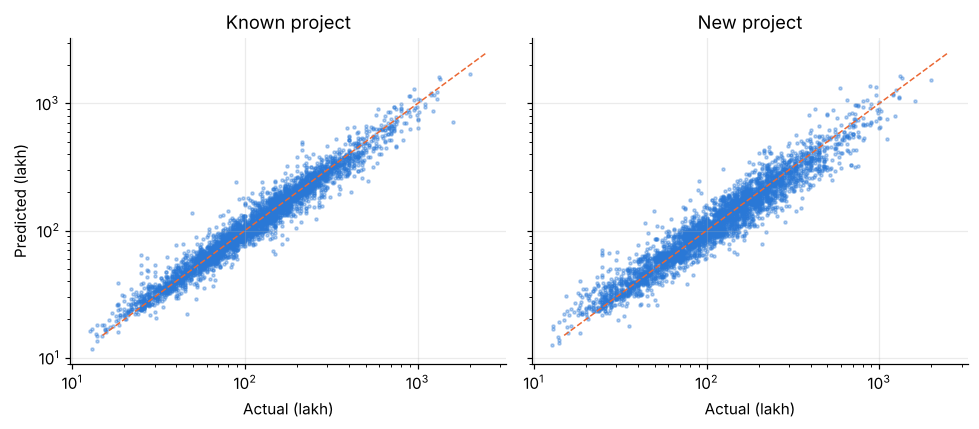

In [10]:
o = pd.read_parquet(ROOT / "data/oof_sample.parquet")
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, col, t in zip(axes, ["known_lakh", "new_lakh"], ["Known project", "New project"]):
    ax.scatter(o.actual_lakh, o[col], s=4, alpha=0.35, color=BLUE)
    ax.plot([15, 2500], [15, 2500], color=ORANGE, lw=1, ls="--")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(t); ax.set_xlabel("Actual (lakh)")
axes[0].set_ylabel("Predicted (lakh)"); plt.tight_layout()

### Price ranges that actually hold

Each estimate comes with an 80% range taken from the model's own cross-validated errors (limits set on 4 folds,
checked on the 5th). One width for all of Mumbai covered 80% overall but not in each zone, so each zone gets its own.

In [11]:
iv = json.load(open(ROOT / "models/intervals.json"))
n8 = iv["New project"]["0.8"]
pd.DataFrame({"one width": n8["coverage_by_zone_one_width"], "per zone": n8["coverage_by_zone"],
              "range low %": {z: round(100 * (np.exp(v["lo"]) - 1)) for z, v in n8["by_zone"].items()},
              "range high %": {z: round(100 * (np.exp(v["hi"]) - 1)) for z, v in n8["by_zone"].items()}})

,one width,per zone,range low %,range high %
South Mumbai,65.9,79.7,-30,41
Western Suburbs,76.0,79.9,-25,33
Central Suburbs,79.1,79.9,-23,32
Thane,72.0,80.0,-26,39
Navi Mumbai & Panvel,79.3,79.9,-23,31
Mira Road & Vasai-Virar,91.2,79.9,-17,19
Kalyan-Dombivli & beyond,84.5,79.7,-20,27


## 5. Price drivers

A linear model on log price with a fixed effect for each locality, so every effect compares flats **in the same
locality**. Standard errors are clustered by project (flats in one project are not independent).

In [12]:
dr = json.load(open(ROOT / "models/drivers.json"))
print("R² (log price):", dr["r2_log"])
pd.DataFrame(dr["effects"]).T

R² (log price): 0.922


,effect_pct,low_pct,high_pct
"10% more area (same BHK, locality)",5.1,4.8,5.3
Under construction (vs ready to move),1.8,0.6,3.1
Resale (vs new),-3.9,-5.1,-2.6
Studio (vs 1 BHK flat),-27.6,-30.0,-25.1
"1 BHK (vs 2 BHK, same area)",-23.6,-24.6,-22.7
"3 BHK (vs 2 BHK, same area)",33.3,31.6,35.1
"4 BHK (vs 2 BHK, same area)",78.8,73.9,83.8


* **Bedrooms carry size information the area figure misses.** At the same stated area a 3 BHK lists ~33% above a 2 BHK.
  Listings mix *carpet* area and *built-up / super built-up* area (often 20-40% bigger), so the bedroom count is the
  cleaner size signal.
* **No discount for waiting.** Under-construction flats list about the same as ready ones (+1.8%); resale flats ~4%
  below new.

In [13]:
pd.DataFrame(dr["under_construction_by_zone"]).T

,effect_pct,low_pct,high_pct,n
Central Suburbs,-0.3,-3.5,3.1,7059.0
Kalyan-Dombivli & beyond,5.7,2.6,9.0,6924.0
Mira Road & Vasai-Virar,0.5,-1.1,2.2,10988.0
Navi Mumbai & Panvel,4.2,-0.3,8.9,7784.0
South Mumbai,-0.8,-6.5,5.2,2464.0
Thane,4.3,-0.4,9.2,7596.0
Western Suburbs,-0.4,-2.6,1.8,11783.0


In [14]:
imp = json.load(open(ROOT / "models/importance.json"))
pd.DataFrame({t: r["increase_pct_points"] for t, r in imp.items()}).rename_axis("feature group (shuffled together)")

,Known project,New project
feature group (shuffled together),,
"Location (zone, locality)",4.1,33.7
Project,43.6,0.0
"Size (area, BHK)",29.0,29.3
Construction status,0.3,0.2
New or resale,0.3,0.7


## 6. Buyer segments (K-Means)

Two features every buyer trades off: **log area** (how big) and **log price per sq ft** (how premium the location),
standardised. The silhouette score is flat from k = 3 to 7: the market is a continuous spread, not separate islands.
k = 5 gives segments a marketing team can name; five other random starts reproduce them.

In [15]:
import joblib
seg = joblib.load(ROOT / "models/segments.joblib")
print("silhouette by k:", {c["k"]: c["silhouette"] for c in seg["curve"]})
print("stability (adjusted Rand index vs 5 other seeds):", seg["stability_ari"])
d.groupby("Segment").agg(share=("Price", lambda x: f"{len(x) / len(d):.0%}"), median_price_lakh=("price_lakh", "median"),
                         median_area=("Area", "median"), median_ppsf=("ppsf", "median"),
                         typical_bhk=("BHK", lambda x: x.mode()[0])).sort_values("median_price_lakh")

silhouette by k: {2: 0.354, 3: 0.381, 4: 0.366, 5: 0.356, 6: 0.356, 7: 0.356, 8: 0.349}
stability (adjusted Rand index vs 5 other seeds): [0.998, 0.994, 0.995, 0.993, 0.987]


,share,median_price_lakh,median_area,median_ppsf,typical_bhk
Segment,,,,,
Budget starter homes,25%,45.0,672.0,6846.5,1
Compact city homes,20%,90.0,550.0,16500.0,1
Spacious value homes,24%,99.0,1090.0,9209.0,2
Premium family homes,21%,200.0,970.0,20909.0,2
Large luxury homes,10%,380.0,1800.0,20625.0,3


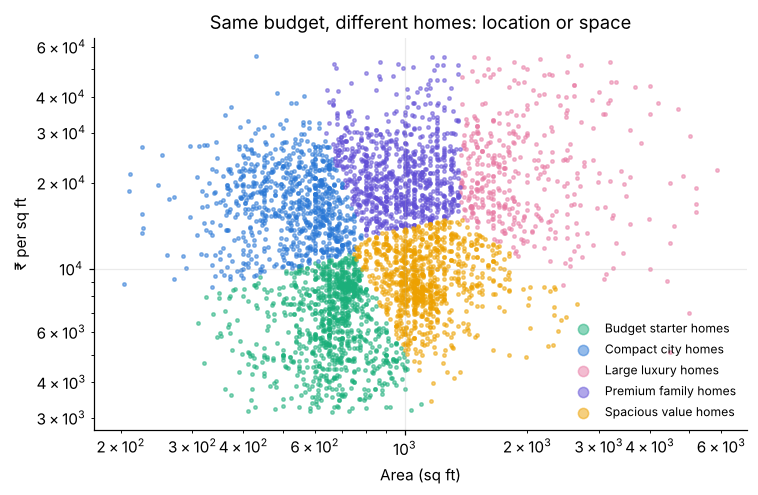

In [16]:
m = d.sample(4000, random_state=1)
fig, ax = plt.subplots(figsize=(7, 4.6))
cols = {"Budget starter homes": AQUA, "Spacious value homes": "#eda100", "Compact city homes": BLUE,
        "Premium family homes": "#6250d6", "Large luxury homes": "#e87ba4"}
for n, g in m.groupby("Segment"):
    ax.scatter(g.Area, g.ppsf, s=5, alpha=0.5, color=cols[n], label=n)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Area (sq ft)"); ax.set_ylabel("₹ per sq ft")
ax.legend(markerscale=3, fontsize=8, frameon=False); ax.set_title("Same budget, different homes: location or space")
plt.tight_layout()

**The key trade-off.** *Compact city homes* (~550 sq ft in the western and central suburbs) and *Spacious value homes*
(~1,090 sq ft in Navi Mumbai, Mira Road and Thane's edges) cost about the same, ₹0.9-1 crore. Buyers at that budget
choose between location and space; a developer chooses which of them to build for.

## 7. Limits

* Asking prices, not sale prices; no dates, so no trends.
* Carpet and built-up area are mixed.
* No floor, view, amenities, parking or builder: most of the remaining error, especially in South Mumbai and Thane.
* The segments describe homes; the buyer labels are an interpretation.